In [1]:
# Logistic Regression

In [2]:
# 1. Import libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [4]:
# 2. Load dataset

In [5]:
df = pd.read_csv("adtech_logistic_dataset.csv")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

   clicks  session_time  cart_adds  converted
0      53     13.706722          4          1
1      52     11.564051          5          1
2      54      8.905086          1          1
3      38      4.539688          6          1
4      55      6.350433          3          1

Dataset Shape: (10000, 4)

Missing Values:
 clicks          0
session_time    0
cart_adds       0
converted       0
dtype: int64

Duplicates: 0


In [6]:
# 3. Check target distribution


Conversion Distribution:
converted
1    9936
0      64
Name: count, dtype: int64


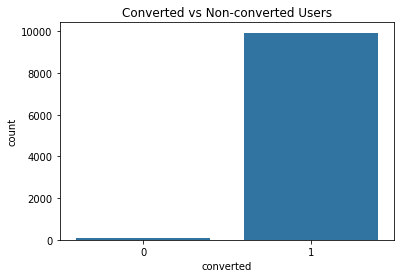

In [7]:
print("\nConversion Distribution:")
print(df["converted"].value_counts())

sns.countplot(data=df, x="converted")
plt.title("Converted vs Non-converted Users")
plt.show()

In [8]:
# 4. Define input and target

In [9]:
X = df.drop("converted", axis=1)
y = df["converted"]

In [10]:
# 5. Handle invalid session times

In [11]:
# Negative session time is not valid.
X = X.copy()
X.loc[X["session_time"] < 0, "session_time"] = float("nan")
X["session_time"] = X["session_time"].fillna(
    X["session_time"].median()
)

In [12]:
# 6. Train-test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
# 7. Build Logistic Regression model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [16]:
# 8. Train model

In [17]:
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [18]:
# 9. Predictions

In [19]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [20]:
# 10. Evaluation

In [21]:
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Accuracy: 0.9665
Precision: 0.998960498960499
Recall: 0.9672873678912934
F1 Score: 0.9828688315008949

Classification Report:
              precision    recall  f1-score   support

           0       0.14      0.85      0.25        13
           1       1.00      0.97      0.98      1987

    accuracy                           0.97      2000
   macro avg       0.57      0.91      0.62      2000
weighted avg       0.99      0.97      0.98      2000



In [22]:
# 11. Confusion Matrix

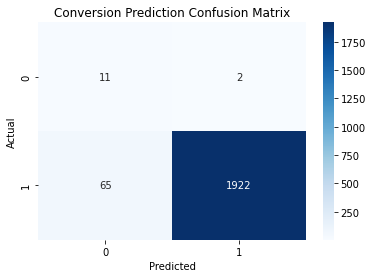

In [23]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Conversion Prediction Confusion Matrix")
plt.show()

In [24]:
# 12. Predict a new user session

In [25]:
new_session = pd.DataFrame({
    "clicks": [55],
    "session_time": [12.5],
    "cart_adds": [4]
})

prediction = model.predict(new_session)[0]
probability = model.predict_proba(new_session)[0][1]

print("\nConversion Prediction:", prediction)
print("Conversion Probability:", round(probability, 4))

if prediction == 1:
    print("User is likely to convert")
else:
    print("User is unlikely to convert")


Conversion Prediction: 1
Conversion Probability: 0.9999
User is likely to convert


In [26]:
# Linear Regression

In [27]:
# 1. Import libraries

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [29]:
# 2. Load dataset

In [30]:
df = pd.read_csv("adtech_regression_dataset.csv")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

   clicks  session_time  cart_adds     revenue
0      34      8.247081          2  321.174533
1      51      7.482857          3  388.433480
2      58      8.766434          4  470.364412
3      50     10.851948          6  599.150770
4      51      8.997615          6  600.518679

Dataset Shape: (10000, 4)

Missing Values:
 clicks          0
session_time    0
cart_adds       0
revenue         0
dtype: int64

Duplicates: 0


In [31]:
# 3. Statistical summary

In [32]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
             clicks  session_time     cart_adds       revenue
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      49.930600      9.965053      4.994000    549.397918
std        7.065081      2.985103      2.246524    130.438381
min       26.000000     -1.244130      0.000000    152.067554
25%       45.000000      7.937888      3.000000    458.737857
50%       50.000000      9.953982      5.000000    544.836078
75%       55.000000     11.997046      6.000000    632.406460
max       77.000000     21.504768     16.000000   1131.812829


In [33]:
# 4. Correlation heatmap

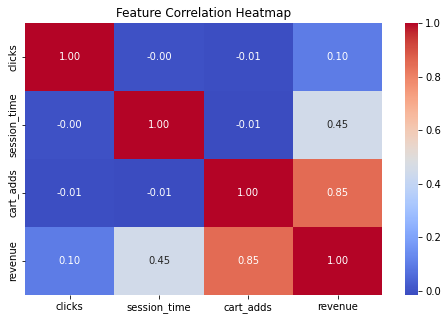

In [34]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [35]:
# 5. Define input and target

In [36]:
X = df.drop("revenue", axis=1)
y = df["revenue"]

In [37]:
# 6. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [38]:
# 7. Build Linear Regression model

In [39]:
model = LinearRegression()

In [40]:
# 8. Train model

In [41]:
model.fit(X_train, y_train)

LinearRegression()

In [42]:
# 9. Predict revenue

In [43]:
y_pred = model.predict(X_test)

In [44]:
# 10. Compare actual and predicted revenue

In [45]:
results = pd.DataFrame({
    "Actual Revenue": y_test.values,
    "Predicted Revenue": y_pred
})

print("\nActual vs Predicted Revenue:")
print(results.head(10))


Actual vs Predicted Revenue:
   Actual Revenue  Predicted Revenue
0      619.219339         655.129999
1      501.610845         514.563880
2      513.828928         534.485884
3      493.174614         534.493360
4      569.495545         578.875772
5      449.982118         478.425240
6      568.630461         553.384316
7      400.429441         457.036378
8      426.252799         422.149555
9      537.160400         524.481721


In [46]:
# 11. Model evaluation

In [47]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
------------------------
MAE: 23.89746278363775
MSE: 911.1355691256833
RMSE: 30.18502226478694
R2 Score: 0.9453792728343063


In [48]:
# 12. Actual vs Predicted visualization

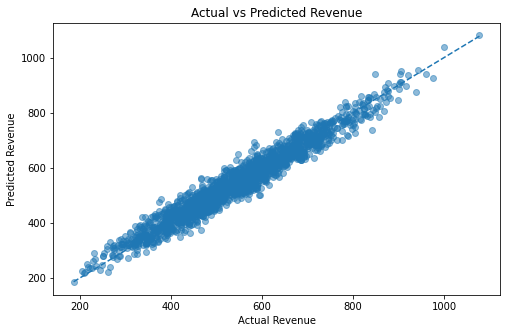

In [49]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [50]:
# 13. Feature coefficient interpretation

In [51]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nFeature Coefficients:")
print(coefficients)

print("\nIntercept:", model.intercept_)


Feature Coefficients:
        Feature  Coefficient
0        clicks      1.99717
1  session_time     20.00087
2     cart_adds     49.89209

Intercept: 1.4713920872834478


In [52]:
# 14. Predict revenue for a new user

In [53]:
new_user = pd.DataFrame({
    "clicks": [50],
    "session_time": [12],
    "cart_adds": [4]
})

predicted_revenue = model.predict(new_user)

print("\nPredicted Customer Revenue:",
      round(predicted_revenue[0], 2))


Predicted Customer Revenue: 540.91
